# Bab 14 — Learning to write like Shakespeare: long short-term memory

**Mahasiswa:** Tarannia Raisha Putri · 101032300231 · TK4702 · Deep Learning

**Referensi utama:** Andrew W. Trask, *Grokking Deep Learning*, Manning (2019), Bab 14, halaman cetak 265–280 (PDF 286–301, indeks PDF mulai 1). Subbab spesifik dicantumkan pada setiap tahap.

**Tujuan pembelajaran:** Menyiapkan batch sekuens, melatih RNN dan LSTM, menjelaskan detach, dan membedakan loss token dari perplexity.

## Ringkasan

Bab ini mengembangkan model bahasa karakter pada berkas Shakespeare asli buku. Truncated BPTT membatasi panjang graph yang disimpan. Demonstrasi gradien menghilang/meledak memotivasi LSTM dengan gerbang forget/input/output dan cell state.

## Konsep, intuisi, dan notasi

RNN biasa: $h_t=\phi(x_tW_{xh}+h_{t-1}W_{hh}+b)$, output logits $z_t=h_tW_{hy}+b_y$. Backprop berulang mengalikan Jacobian; norm produk dapat menyusut/meledak.

LSTM: $f_t=\sigma(x_tW_{xf}+h_{t-1}W_{hf}+b_f)$; $i_t,o_t$ memiliki bentuk serupa, $g_t=\tanh(x_tW_{xg}+h_{t-1}W_{hg}+b_g)$; $c_t=f_t\odot c_{t-1}+i_t\odot g_t$, $h_t=o_t\odot\tanh(c_t)$. Untuk batch B, state $(B,H)$, embedding $(V,H)$, tiap matriks gerbang $(H,H)$, decoder $(H,V)$.

Jalur penyalinan cell menyediakan kontribusi turunan langsung $\partial c_t/\partial c_{t-1}=f_t$ jika jalur gerbang lain ditahan. Ini membantu penyimpanan informasi tetapi tidak menjamin semua gradien stabil. Truncated BPTT memutus **graph** di batas chunk, mempertahankan **nilai** state. Loss dilaporkan sebagai NLL mean per karakter dan perplexity adalah eksponensialnya.

## Persiapan dan cara membaca

Jalankan **Restart Kernel → Run All**. Semua penjelasan merupakan parafrasa orisinal; angka hasil berada pada output sel yang benar-benar dijalankan. Label **reproduksi** berarti algoritme/contoh buku ditulis ulang; **koreksi/penyesuaian** menunjukkan perubahan; **tambahan** menunjukkan eksperimen atau interpretasi praktikum. `GDL_MODE=quick` mengurangi latihan berat; `full` memilih anggaran buku, dengan perubahan yang tetap dicatat. Keberhasilan eksekusi tidak membuktikan kesamaan akurasi dengan buku.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'src').is_dir(), 'Jalankan dari root repository atau notebooks/'
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
MODE = os.environ.get('GDL_MODE', 'quick')
assert MODE in {'quick', 'full'}
FULL = MODE == 'full'
np.random.seed(1)
np.set_printoptions(precision=6, suppress=True)
METRICS = {}
def record(**values):
    METRICS.update(values)
def finite(*arrays):
    assert all(np.isfinite(np.asarray(a)).all() for a in arrays), 'NaN/inf terdeteksi'
def softmax(z):
    z = np.asarray(z)
    e = np.exp(z - np.max(z, axis=-1, keepdims=True))
    return e / e.sum(axis=-1, keepdims=True)
def sigmoid(z):
    return np.exp(-np.logaddexp(0, -np.asarray(z)))
print('Mode:', MODE, '| NumPy:', np.__version__)

Mode: quick | NumPy: 2.5.4


<a id="b14-batch"></a>

## Reproduksi: character model dan truncated BPTT

**Sumber:** cetak 266–271; PDF 287–292.

Berkas `shakespear.txt` memiliki sekitar 100 ribu karakter dari pendamping buku. Quick memakai 8.000 karakter pertama untuk training dan 2.000 karakter terakhir untuk evaluasi tambahan, sehingga tidak tumpang tindih. Full memakai seluruh corpus seperti listing dan tidak mengklaim test held-out. Vocabulary karakter dibuat dari corpus penuh seperti buku.

RNN full: embedding/hidden 512, batch32, bptt16, 100 epoch. LSTM full: 512, batch16, bptt25, 110 epoch (10+100 pemanggilan upstream). Quick: hidden32, batch8, 2 epoch RNN/3 epoch LSTM. Ini konfigurasi berbeda, bukan pelatihan penuh yang dipercepat secara ekuivalen.

In [2]:
from src.datasets import fetch
from src.autograd import Tensor,SGD,Linear,Layer,Embedding,RNNCell
raw=fetch('shakespear.txt').read_text()
vocab=sorted(set(raw)); lookup={c:i for i,c in enumerate(vocab)}
indices=np.array([lookup[c] for c in raw])
train_indices=indices if FULL else indices[:8000]
test_indices=None if FULL else indices[-2000:]
def make_batches(indices,batch_size,bptt):
    steps=len(indices)//batch_size
    matrix=indices[:steps*batch_size].reshape(batch_size,steps).T
    chunks=(steps-1)//bptt
    inputs=matrix[:-1][:chunks*bptt].reshape(chunks,bptt,batch_size)
    targets=matrix[1:][:chunks*bptt].reshape(chunks,bptt,batch_size)
    np.testing.assert_array_equal(inputs[:,1:,:],targets[:,:-1,:])
    return inputs,targets
example_inputs,example_targets=make_batches(train_indices,8,16)
print('Karakter total:',len(raw),'vocab:',len(vocab),'train:',len(train_indices))
print('Awal corpus:',repr(raw[:5]),'indeks:',indices[:5])
print('Bentuk batch:',example_inputs.shape,'target:',example_targets.shape)
print('Input waktu pertama:',example_inputs[0,:5,0],'target:',example_targets[0,:5,0])

Karakter total: 99993 vocab: 62 train: 8000
Awal corpus: 'That,' indeks: [29 43 36 55  4]
Bentuk batch: (62, 16, 8) target: (62, 16, 8)
Input waktu pertama: [29 43 36 55  4] target: [43 36 55  4  1]


<a id="b14-unstable"></a>

## Reproduksi: vanishing/exploding gradients

**Sumber:** cetak 272–273; PDF 293–294.

Matriks [[1,4],[4,1]] digunakan berulang seperti buku. Sigmoid yang tersaturasi memberi derivative kecil, sedangkan ReLU aktif membiarkan efek penguatan matriks. Seluruh angka dihitung, bukan disalin dari output cetak.

sigmoid aktivasi akhir: [0.993073 0.993073] gradien akhir: [0. 0.]
relu aktivasi akhir: [9697977.65594 9697977.65594] gradien akhir: [9765625. 9765625.]


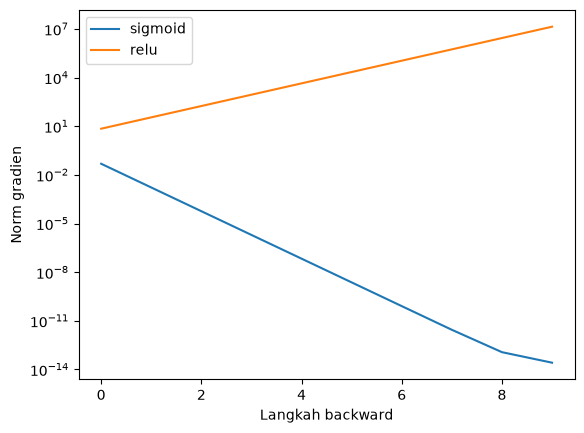

In [3]:
W=np.array([[1.,4.],[4.,1.]])
activation=sigmoid(np.array([1.,.01])); norms={}
for name,fun,derivative in [('sigmoid',sigmoid,lambda h:h*(1-h)),('relu',lambda x:np.maximum(0,x),lambda h:h>0)]:
    activations=[]
    for _ in range(10): activation=fun(activation@W); activations.append(activation)
    grad=np.ones_like(activation); trace=[]
    for h in reversed(activations): grad=(derivative(h)*grad)@W.T; trace.append(np.linalg.norm(grad))
    norms[name]=trace
    print(name,'aktivasi akhir:',activation,'gradien akhir:',grad)
    plt.semilogy(trace,label=name)
finite(*norms.values()); assert norms['sigmoid'][-1]<1e-10 and norms['relu'][-1]>1e6
plt.xlabel('Langkah backward'); plt.ylabel('Norm gradien'); plt.legend(); plt.show()

<a id="b14-lstm"></a>

## Reproduksi: LSTM gates dan layer

**Sumber:** cetak 274–277; PDF 295–298.

Kode mempertahankan empat pasangan Linear dan decoder tanpa bias seperti halaman 276. Hidden dan cell diawali nol dengan komponen pertama 1 sesuai listing. Decoder LSTM diawali nol pada latihan. Gerbang f mengatur yang disimpan, i informasi yang masuk, o bagian cell yang terlihat di output.

In [4]:
class LSTMCell(Layer):
    def __init__(self,n_inputs,n_hidden,n_output):
        self.n_hidden=n_hidden
        self.input_layers=[Linear(n_inputs,n_hidden) for _ in range(4)]
        self.hidden_layers=[Linear(n_hidden,n_hidden,bias=False) for _ in range(4)]
        self.w_ho=Linear(n_hidden,n_output,bias=False)
    def forward(self,x,hidden):
        previous_h,previous_c=hidden
        pre=[a(x)+b(previous_h) for a,b in zip(self.input_layers,self.hidden_layers)]
        f,i,o=pre[0].sigmoid(),pre[1].sigmoid(),pre[2].sigmoid()
        g=pre[3].tanh()
        c=f*previous_c+i*g; h=o*c.tanh()
        return self.w_ho(h),(h,c)
    def init_hidden(self,batch_size=1):
        h=np.zeros((batch_size,self.n_hidden)); c=np.zeros_like(h)
        h[:,0]=1.; c[:,0]=1.
        return Tensor(h,True),Tensor(c,True)
    def get_parameters(self):
        return [p for layer in self.input_layers+self.hidden_layers+[self.w_ho] for p in layer.get_parameters()]
def detach(hidden):
    return tuple(h.detach() for h in hidden) if isinstance(hidden,tuple) else hidden.detach()
# Tambahan: graph lama dilepas tanpa mereset nilainya.
state=Tensor([[.2,.3]],True).tanh(); detached=detach(state)
np.testing.assert_allclose(detached.data,state.data); assert detached.parents==()

<a id="b14-training"></a>

## Reproduksi: RNN, LSTM training, dan sampling

**Sumber:** cetak 270–280; PDF 291–301.

Loop menjumlahkan loss sepanjang chunk dan melakukan backward **sekali pada jumlah tersebut**. Listing RNN memiliki loop `for loss in losses` yang menimpa variabel total; koreksi ini memastikan semua timestep dipakai. Framework memakai CE mean per batch. Penjumlahan sepanjang waktu mempertahankan skala temporal; log membagi bptt sebelum menghitung perplexity.

Sampling greedy tersedia seperti buku; sampling probabilistik tambahan memakai `rng.choice(p=...)`, mengganti perbandingan threshold satu nilai yang bukan categorical sampling. Sampling tidak menyimpan graph panjang: state didetach tiap karakter. Learning rate turun 0,99 setiap epoch. Tidak ada janji teks hasil quick sudah menyerupai karya Shakespeare.

In [5]:
def sample(embed,model,n=100,initial='T',temperature=1.,greedy=False):
    rng=np.random.RandomState(5); hidden=model.init_hidden(1); token=lookup[initial]; text=''
    for _ in range(n):
        logits,hidden=model(embed(np.array([token])),detach(hidden))
        p=softmax(logits.data[0]/temperature)
        token=int(p.argmax()) if greedy else int(rng.choice(len(vocab),p=p))
        text+=vocab[token]
    return text

def train_language(kind):
    np.random.seed(0); dim=512 if FULL else 32
    batch=(32 if kind=='rnn' else 16) if FULL else 8
    bptt=16 if kind=='rnn' else 25
    epochs=(100 if kind=='rnn' else 110) if FULL else (2 if kind=='rnn' else 3)
    embed=Embedding(len(vocab),dim)
    model=RNNCell(dim,dim,len(vocab)) if kind=='rnn' else LSTMCell(dim,dim,len(vocab))
    if kind=='lstm': model.w_ho.weight.data*=0
    optim=SGD(embed.get_parameters()+model.get_parameters(),.05)
    inputs,targets=make_batches(train_indices,batch,bptt); history=[]
    for epoch in range(epochs):
        hidden=model.init_hidden(batch); total=0.
        for xb,yb in zip(inputs,targets):
            hidden=detach(hidden); losses=[]
            for t in range(bptt):
                output,hidden=model(embed(xb[t]),hidden)
                losses.append(output.cross_entropy(yb[t]))
            loss=sum(losses); loss.backward(); optim.step()
            total+=loss.data.item()/bptt
        mean_nll=total/len(inputs); history.append(mean_nll)
        print(kind,'epoch',epoch+1,'NLL',mean_nll,'perplexity',np.exp(mean_nll))
        optim.alpha*=.99
    print(kind,'greedy:',repr(sample(embed,model,100,greedy=True)))
    print(kind,'sampling:',repr(sample(embed,model,100,temperature=.8)))
    test_ppl=None
    if test_indices is not None:
        hidden=model.init_hidden(1); losses=[]
        for token,target in zip(test_indices[:-1],test_indices[1:]):
            output,hidden=model(embed(np.array([token])),detach(hidden))
            losses.append(output.cross_entropy([target]).data.item())
        test_ppl=float(np.exp(np.mean(losses))); print(kind,'held-out perplexity:',test_ppl)
    finite(history,*[p.data for p in model.get_parameters()])
    return model,embed,history,test_ppl
rnn,rnn_embed,rnn_history,rnn_test=train_language('rnn')
lstm,lstm_embed,lstm_history,lstm_test=train_language('lstm')
record(train_characters=len(train_indices),rnn_epochs=len(rnn_history),lstm_epochs=len(lstm_history),rnn_final_nll=rnn_history[-1],lstm_final_nll=lstm_history[-1],rnn_test_perplexity=rnn_test,lstm_test_perplexity=lstm_test)

rnn epoch 1 NLL 3.360445868703783 perplexity 28.80202994051807


rnn epoch 2 NLL 3.191139564877439 perplexity 24.316121458503602
rnn greedy: 'e to to to to to to to to to to to to to to to to to to to to to to to to to to to to to to to to to'
rnn sampling: 'at uinoha, re te: onibd e auu, bor n\nioy srt\nhweohoe I dunreeottr g np be sefd uu te hhud\nt ise,i\nne'


rnn held-out perplexity: 21.533773642711193


lstm epoch 1 NLL 3.6345462566177695 perplexity 37.884659083300406


lstm epoch 2 NLL 3.300058036377587 perplexity 27.114212485669235


lstm epoch 3 NLL 3.2162277123135286 perplexity 24.93388476506113
lstm greedy: 'oe tee tee tee tee tee tee tee tee tee tee tee tee tee tee tee tee tee tee tee tee tee tee tee tee t'
lstm sampling: 'FsDufkohbI rh teeanindWae avua cor n\nknwarst\nhweoirf Saeunrhistsp h nr bfdoeiintt te hiue\nt lsgeo nh'


lstm held-out perplexity: 23.198111361020644


<a id="b14-checks"></a>

## Tambahan: gradient check satu langkah LSTM

**Sumber:** cetak 276–276; PDF 297–297.

Autograd sudah diuji pada Bab 13, tetapi uji ini memeriksa komposisi gerbang dan kedua state. Parameter diuji sebelum diubah; loss harus berhubungan dengan semua cabang yang ingin diperiksa.

In [6]:
np.random.seed(3); small=LSTMCell(2,2,3); x=Tensor([[.1,-.2]])
def loss_one():
    output,_=small(x,small.init_hidden(1)); return output.cross_entropy([2])
loss_one().backward(); grads=[p.grad.copy() for p in small.get_parameters()]
eps=1e-6; errors=[]
for param,grad in zip(small.get_parameters(),grads):
    idx=tuple(0 for _ in param.data.shape); old=param.data[idx]
    param.data[idx]=old+eps; plus=loss_one().data.item()
    param.data[idx]=old-eps; minus=loss_one().data.item(); param.data[idx]=old
    errors.append(abs((plus-minus)/(2*eps)-grad[idx]))
assert max(errors)<1e-7
print('Galat gradien LSTM:',max(errors)); record(lstm_gradient_max_error=float(max(errors)))

Galat gradien LSTM: 1.678639954360954e-10


## Analisis output aktual — run tersimpan

Mode **quick**, eksekusi 2026-10-16T01:51:15.940954+07:00. Ringkasan ini dibuat dari output validator, bukan angka contoh dalam buku.

RNN 2 epoch dan LSTM 3 epoch memakai 8,000 karakter training. NLL akhir masing-masing 3.1911 dan 3.2162. Held-out perplexity RNN 21.534, LSTM 23.198. LSTM tidak lebih baik pada run ini; arsitektur lebih kompleks memerlukan anggaran/tuning yang sesuai. Galat gradient check gerbang 1.679e-10; kualitas teks harus dibaca pada sampel aktual.

## Kesimpulan dan pembahasan pertanyaan

Run quick mengeksekusi batch, BPTT, RNN, LSTM, sampling, dan evaluasi held-out, dengan ukuran lebih kecil. Teks keluaran boleh belum koheren. LSTM membantu aliran gradien tetapi tidak menjamin unggul pada setiap run singkat.

**Apa yang dipertahankan setelah detach?** Nilai hidden/cell, sementara hubungan graph ke chunk sebelumnya dilepas.

**Mengapa LSTM punya dua state?** Cell memegang jalur memori, hidden merupakan keluaran terkontrol untuk langkah berikutnya/decoder.

**Mengapa argmax(z×15) tidak mengubah sampel greedy?** Perkalian positif tidak mengubah urutan logits.

**Apakah perplexity training menunjukkan kualitas sastra?** Tidak; periksa teks aktual dan data yang benar-benar tidak dilatih.

In [7]:
finite(*[v for v in METRICS.values() if isinstance(v, (int, float))])
print('VALIDATION_METRICS=' + json.dumps(METRICS, sort_keys=True))

VALIDATION_METRICS={"lstm_epochs": 3, "lstm_final_nll": 3.2162277123135286, "lstm_gradient_max_error": 1.678639954360954e-10, "lstm_test_perplexity": 23.198111361020644, "rnn_epochs": 2, "rnn_final_nll": 3.191139564877439, "rnn_test_perplexity": 21.533773642711193, "train_characters": 8000}
